In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
grid = gpd.read_file(
    "C:/Floor/Documenten/ENV-year-2/Thesis/Data/Schildersbuurt/master_grid_schildersbuurt.gpkg",
    layer="master_grid_with_features",
)
# Reproject to EPSG:28992 (RD New - meters) so calculations work properly
grid = grid.to_crs("EPSG:28992")

#remove a few columns
grid.drop(
    columns=['LST_2025-07-25 16:45', 'LST_2025-08-19 06:10'], inplace=True)

# show the columns of the grid
grid.columns

Index(['grid_id', 'percentage_verharding', 'percentage_onverhard',
       'percentage_water', 'percentage_green_shadow', 'percentage_grey_shadow',
       'percentage_combined_shadow', 'boomkroonvolume_m3',
       'boomkroonoppervlakte_m2', 'biomassa_bermudez_kg',
       'LST_2025-06-02 13:54', 'LST_2025-06-02 15:30', 'LST_2025-06-03 13:05',
       'LST_2025-06-04 12:18', 'LST_2025-06-05 13:06', 'LST_2025-06-06 12:17',
       'LST_2025-06-09 11:29', 'LST_2025-06-11 11:29', 'LST_2025-06-12 09:04',
       'LST_2025-06-15 09:51', 'LST_2025-06-16 09:03', 'LST_2025-06-18 07:26',
       'LST_2025-06-29 04:58', 'LST_2025-06-30 04:10', 'LST_2025-07-10 22:26',
       'LST_2025-07-11 21:37', 'LST_2025-07-30 15:55', 'LST_2025-08-06 11:52',
       'LST_2025-08-09 12:39', 'LST_2025-08-10 11:50', 'LST_2025-08-11 09:25',
       'LST_2025-08-13 09:24', 'LST_2025-08-13 11:01', 'LST_2025-08-14 10:12',
       'LST_2025-08-15 07:47', 'LST_2025-08-21 06:10', 'LST_2025-08-21 07:47',
       'LST_2025-08-23 06

In [3]:
def determine_time_of_day(column_name):
    """
    Determine the time of day based on the hour in the given column.
    Returns a new column with the time of day categories.
    """
    # Check if it's an LST column
    if not column_name.startswith("LST_"):
        return None
    
    # Extract the time part after the space (e.g., '03:44')
    time_str = column_name.split(" ")[1]
    hour = int(time_str.split(":")[0])
    
    # Use the 6-hour blocks definition
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

In [4]:
lst_columns = [col for col in grid.columns if col.startswith("LST_")]

tod_dict = {"Night": [], "Morning": [], "Afternoon": [], "Evening": []}

for col in lst_columns:
    tod = determine_time_of_day(col)
    if tod:
        tod_dict[tod].append(col)

for tod, columns in tod_dict.items():
    if columns: 
        grid[f"LST_Mean_{tod}"] = grid[columns].mean(axis=1)
    else:
        grid[f"LST_Mean_{tod}"] = np.nan

print(grid[['LST_Mean_Morning',"LST_Mean_Afternoon", 'LST_Mean_Evening', "LST_Mean_Night"]].head())

   LST_Mean_Morning  LST_Mean_Afternoon  LST_Mean_Evening  LST_Mean_Night
0         28.007500            29.28250            19.230       18.420000
1         27.974375            29.23125            19.465       18.330000
2         28.136250            29.68625            19.610       18.003333
3         27.583125            28.49875            18.730       18.286667
4         27.740000            28.97125            18.645       18.463333


Spearman Correlation Matrix:
                            LST_Mean_Morning  LST_Mean_Afternoon  \
LST_Mean_Morning                    1.000000            0.479605   
LST_Mean_Afternoon                  0.479605            1.000000   
LST_Mean_Evening                    0.128269            0.259461   
LST_Mean_Night                      0.114164            0.187898   
boomkroonvolume_m3                 -0.197268           -0.224717   
boomkroonoppervlakte_m2            -0.197266           -0.230072   
biomassa_bermudez_kg               -0.196745           -0.226885   
percentage_green_shadow            -0.187884           -0.187749   
percentage_grey_shadow              0.106901            0.089658   
percentage_combined_shadow         -0.128033           -0.122996   
percentage_onverhard               -0.202254           -0.265984   
percentage_verharding               0.242891            0.263524   

                            LST_Mean_Evening  LST_Mean_Night  \
LST_Mean_Morning      

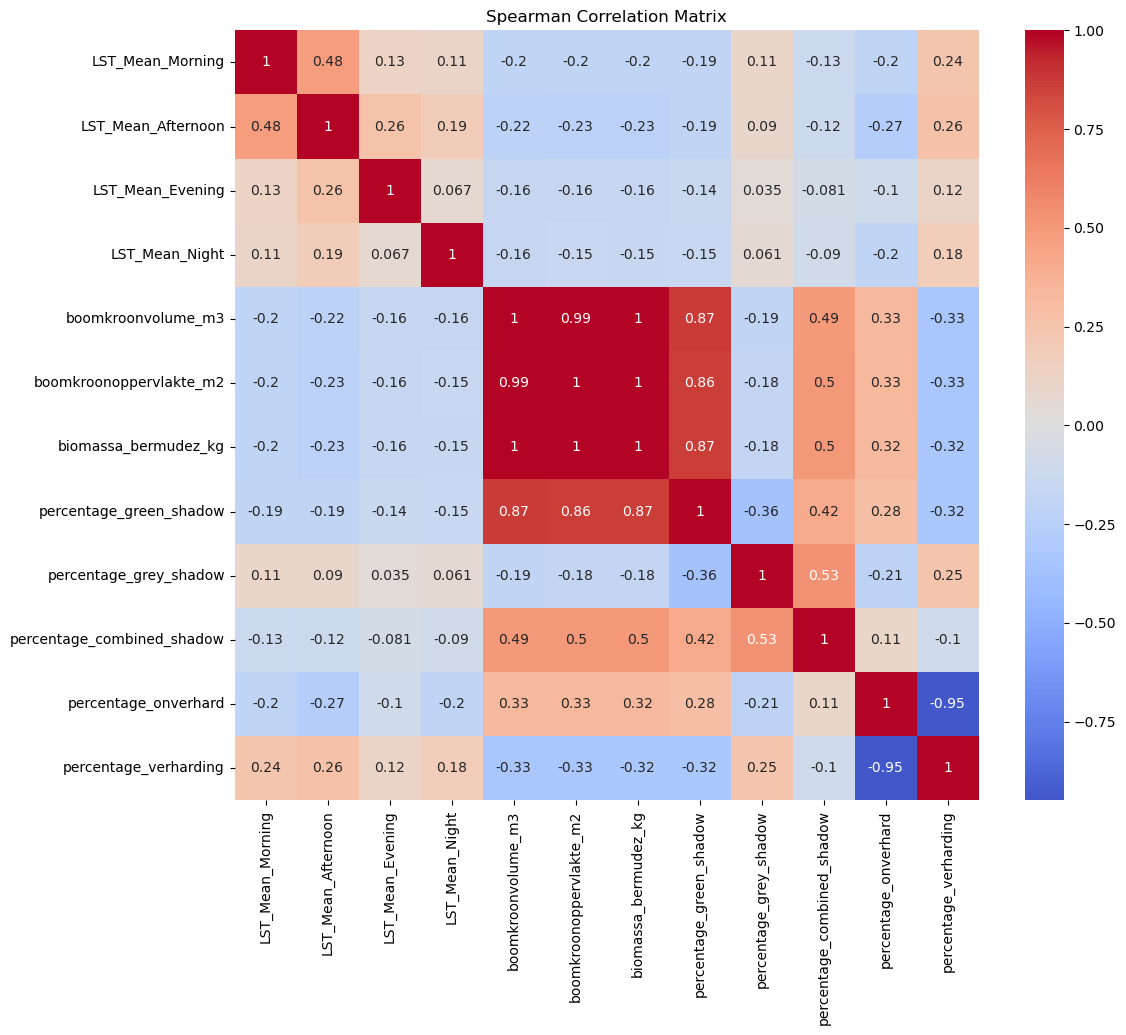

In [5]:
correlation_variables = ['LST_Mean_Morning', 'LST_Mean_Afternoon', 'LST_Mean_Evening', 'LST_Mean_Night',
                         'boomkroonvolume_m3', 'boomkroonoppervlakte_m2', 'biomassa_bermudez_kg',
                         'percentage_green_shadow', 'percentage_grey_shadow', 'percentage_combined_shadow',
                         'percentage_onverhard', 'percentage_verharding']

grid_statistics = grid[correlation_variables].copy()

spearman_corr = grid_statistics.corr(method='spearman')

print("Spearman Correlation Matrix:")
print(spearman_corr)

plt.figure(figsize=(12, 10))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0)
plt.title('Spearman Correlation Matrix')
plt.show()

                            OLS Regression Results                            
Dep. Variable:     LST_Mean_Afternoon   R-squared:                       0.126
Model:                            OLS   Adj. R-squared:                  0.126
Method:                 Least Squares   F-statistic:                     280.1
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          2.24e-114
Time:                        12:59:21   Log-Likelihood:                -4710.9
No. Observations:                3886   AIC:                             9428.
Df Residuals:                    3883   BIC:                             9447.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   30.0172 

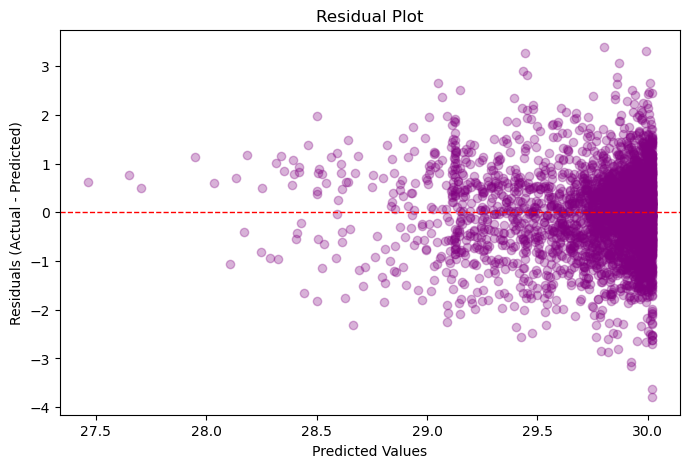

In [7]:
# Ordinary Least Squares (OLS) Regression, Multiple Linear Regression
import statsmodels.api as sm

y = grid['LST_Mean_Afternoon']  # Dependent variable
X = grid[['biomassa_bermudez_kg', 'percentage_onverhard']]  # Independent variables

X = sm.add_constant(X)  # Adds a constant term to the predictor
model = sm.OLS(y, X).fit()  # Fit the model

print(model.summary())  # Print the summary of the regression results

residuals = model.resid

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred, residuals, alpha=0.3, color='purple')
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Residuals (Actual - Predicted)')
ax.set_title('Residual Plot')
plt.show()

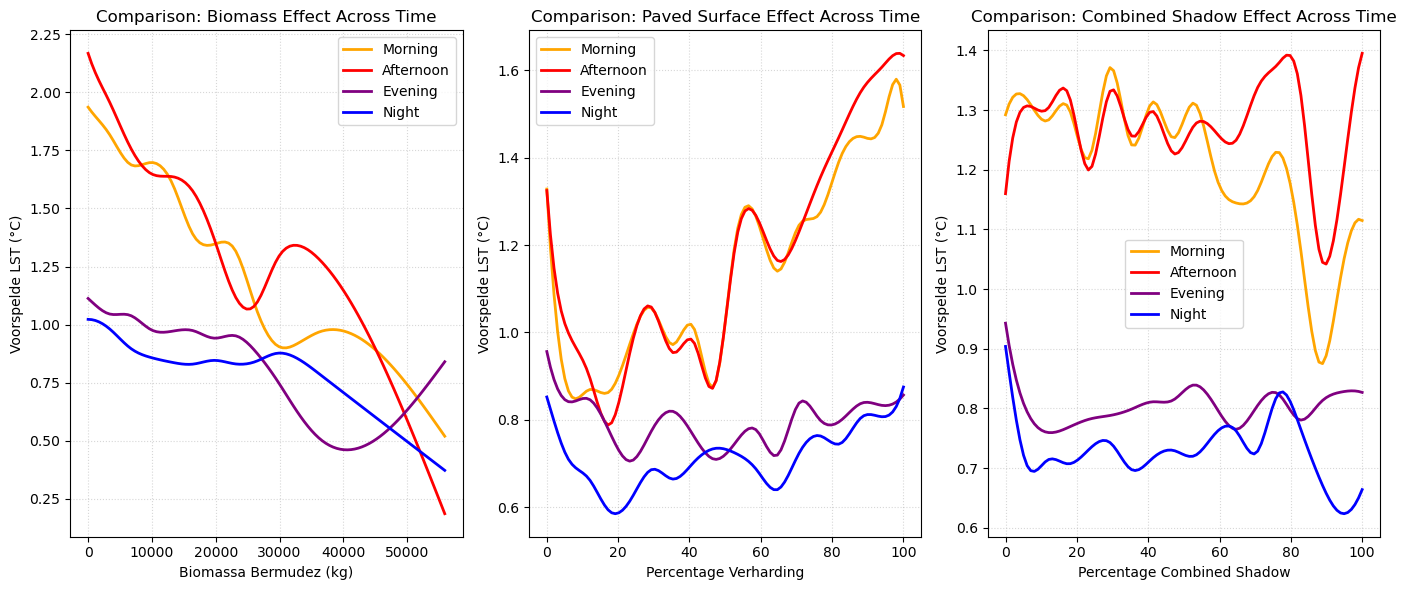

In [23]:
from pygam import LinearGAM, s

X = grid[['biomassa_bermudez_kg', 'percentage_verharding', 'percentage_combined_shadow']]
target_columns = { 
    'Morning': 'LST_Mean_Morning', 
    'Afternoon': 'LST_Mean_Afternoon', 
    'Evening': 'LST_Mean_Evening',
    'Night': 'LST_Mean_Night'
}

# Colors for each time block
colors = {'Night': 'blue', 'Morning': 'orange', 'Afternoon': 'red', 'Evening': 'purple'}

# Create a figure with 2 subplots side by side (one for each variable)
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Loop through all time blocks, fit models, and plot lines on the same axes
for tod, col in target_columns.items():
    y = grid[col]
    gam = LinearGAM(s(0) + s(1) + s(2)).fit(X, y)
    
    # 1. Biomass plot (Term 0)
    XX_bio = gam.generate_X_grid(term=0)
    axs[0].plot(XX_bio[:, 0], gam.partial_dependence(term=0, X=XX_bio), label=tod, color=colors[tod], lw=2)
    
    # 2. Paved surface plot (Term 1)
    XX_paved = gam.generate_X_grid(term=1)
    axs[1].plot(XX_paved[:, 1], gam.partial_dependence(term=1, X=XX_paved), label=tod, color=colors[tod], lw=2)

    # 3. Combined shadow plot (Term 2)
    XX_combined_shadow = gam.generate_X_grid(term=2)
    axs[2].plot(XX_combined_shadow[:, 2], gam.partial_dependence(term=2, X=XX_combined_shadow), label=tod, color=colors[tod], lw=2)

# Format Biomass plot
axs[0].set_title('Comparison: Biomass Effect Across Time')
axs[0].set_xlabel('Biomassa Bermudez (kg)')
axs[0].set_ylabel('Voorspelde LST (°C)')
axs[0].grid(True, linestyle=':', alpha=0.5)
axs[0].legend()

# Format Paved plot
axs[1].set_title('Comparison: Paved Surface Effect Across Time')
axs[1].set_xlabel('Percentage Verharding')
axs[1].set_ylabel('Voorspelde LST (°C)')
axs[1].grid(True, linestyle=':', alpha=0.5)
axs[1].legend()

# Format Combined Shadow plot
axs[2].set_title('Comparison: Combined Shadow Effect Across Time')
axs[2].set_xlabel('Percentage Combined Shadow')
axs[2].set_ylabel('Voorspelde LST (°C)')
axs[2].grid(True, linestyle=':', alpha=0.5)
axs[2].legend()

plt.tight_layout()
plt.show()

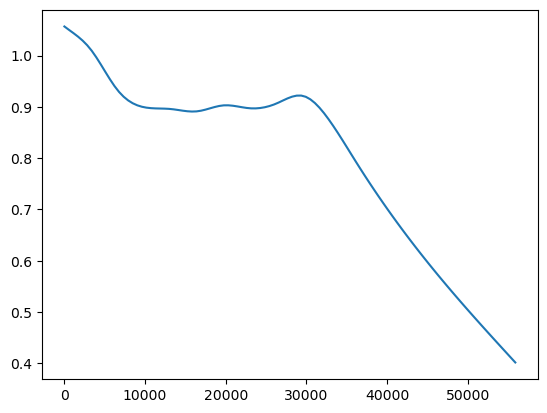